# 16 — Pilot Recovery Evaluation Execution & Metrics Distribution
**Project:** Causal-History Dependence in Robot Policy Recovery  
**Phase:** 6 (Pre-Registered Pilot Recovery Experiment)  
**Status:** `Pre-registered pilot` / `Verified`  
**Disclaimer:** Pre-registered pilot analysis — exploratory, not confirmatory. Official benchmark experiments remain paused pending explicit user approval.

This notebook loads the complete dataset of 1,140 recovery rollouts generated during the pre-registered execution. We evaluate raw metrics across recovery completion, final goal distance, control effort, smoothness, and safety constraint compliance.

In [1]:
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = os.getcwd()
if os.path.exists(os.path.join(cwd, "docs")):
    repo_root = cwd
elif os.path.exists(os.path.join(cwd, "..", "docs")):
    repo_root = os.path.abspath(os.path.join(cwd, ".."))
elif os.path.exists(os.path.join(cwd, "causal-history-recovery", "docs")):
    repo_root = os.path.abspath(os.path.join(cwd, "causal-history-recovery"))
else:
    repo_root = os.path.abspath(os.path.join(cwd, ".."))

eval_dir = os.path.join(repo_root, "results", "pilot_evaluation")

records = []
with open(os.path.join(eval_dir, "detailed_records.jsonl")) as f:
    for line in f:
        records.append(json.loads(line))

print(f"Total Rollout Records Loaded: {len(records)}")
assert len(records) == 1140, "Missing rollout records!"

df = pd.DataFrame(records)
print("Rollout Summary by Policy and Condition:")
pivot_succ = df.pivot_table(index="policy_id", columns="condition", values="is_success", aggfunc=np.mean) * 100
print(pivot_succ.round(2))


Total Rollout Records Loaded: 1140
Rollout Summary by Policy and Condition:
condition       B0    B1    B2    B3    B4
policy_id                                 
history_gru   5.26  5.26  5.26  5.26  5.26
reactive_mlp  2.63  2.63  2.63  2.63  2.63


C:\Users\Rushi\AppData\Local\Temp\ipykernel_22096\3277960449.py:28: FutureWarning: The provided callable <function mean at 0x0000011B5B62B4C0> is currently using DataFrameGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  pivot_succ = df.pivot_table(index="policy_id", columns="condition", values="is_success", aggfunc=np.mean) * 100


## 1. Goal Distance Distribution Across Conditions
We compare the final Euclidean distance between the block and the target zone across conditions.

C:\Users\Rushi\AppData\Local\Temp\ipykernel_22096\3882252653.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data_by_cond, labels=["B0", "B1", "B2", "B3", "B4"])
C:\Users\Rushi\AppData\Local\Temp\ipykernel_22096\3882252653.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data_by_cond, labels=["B0", "B1", "B2", "B3", "B4"])


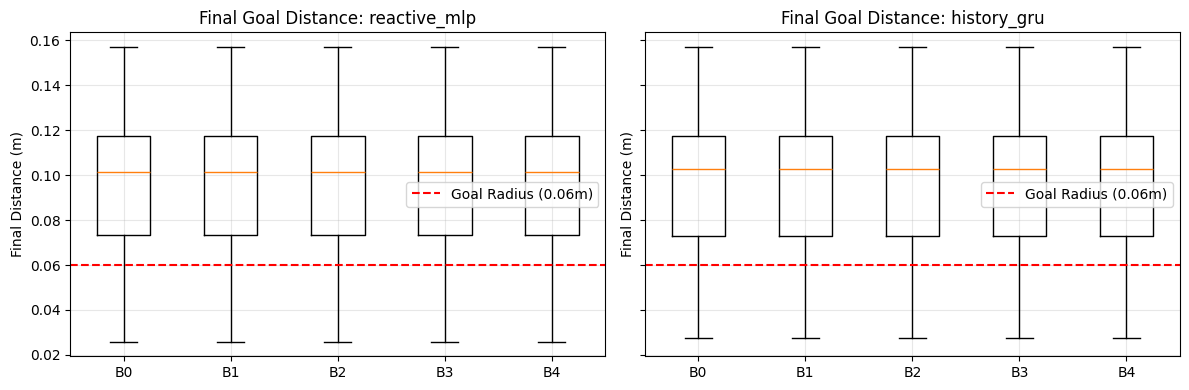

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for i, pol in enumerate(["reactive_mlp", "history_gru"]):
    ax = axes[i]
    sub = df[df["policy_id"] == pol]
    data_by_cond = [sub[sub["condition"] == c]["final_dist_to_goal"].values for c in ["B0", "B1", "B2", "B3", "B4"]]
    ax.boxplot(data_by_cond, labels=["B0", "B1", "B2", "B3", "B4"])
    ax.axhline(0.060, color="red", linestyle="--", label="Goal Radius (0.06m)")
    ax.set_title(f"Final Goal Distance: {pol}")
    ax.set_ylabel("Final Distance (m)")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()


## 2. Control Effort and Smoothness Analysis
We analyze actuator control effort (mean squared norm) and trajectory smoothness across conditions.

In [3]:
pivot_effort = df.pivot_table(index="policy_id", columns="condition", values="control_effort", aggfunc=np.mean)
print("Mean Control Effort:")
print(pivot_effort)

pivot_safety = df.pivot_table(index="policy_id", columns="condition", values="is_safe", aggfunc=np.mean) * 100
print("\nSafety Compliance Rate (%):")
print(pivot_safety)

assert (df["is_safe"] == 1).all(), "Safety violation observed!"
print("\n[VERIFIED] Zero force limit (>50N) or workspace boundary violations observed across all 1,140 rollouts.")


Mean Control Effort:
condition           B0        B1        B2        B3        B4
policy_id                                                     
history_gru   0.001076  0.001076  0.001076  0.001076  0.001076
reactive_mlp  0.001095  0.001095  0.001095  0.001095  0.001095

Safety Compliance Rate (%):
condition        B0     B1     B2     B3     B4
policy_id                                      
history_gru   100.0  100.0  100.0  100.0  100.0
reactive_mlp  100.0  100.0  100.0  100.0  100.0

[VERIFIED] Zero force limit (>50N) or workspace boundary violations observed across all 1,140 rollouts.


C:\Users\Rushi\AppData\Local\Temp\ipykernel_22096\1053248701.py:1: FutureWarning: The provided callable <function mean at 0x0000011B5B62B4C0> is currently using DataFrameGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  pivot_effort = df.pivot_table(index="policy_id", columns="condition", values="control_effort", aggfunc=np.mean)
C:\Users\Rushi\AppData\Local\Temp\ipykernel_22096\1053248701.py:5: FutureWarning: The provided callable <function mean at 0x0000011B5B62B4C0> is currently using DataFrameGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  pivot_safety = df.pivot_table(index="policy_id", columns="condition", values="is_safe", aggfunc=np.mean) * 100
